In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from Risk_Kit.Factor_Risk_Model import risk
from Risk_Kit.Risk_Kit_Utils.Risk_Model_Harness import multiple_model_tracker,run_multiple_risk_models

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:

file_name=Path("..")/"Data/SP500_2016-2025.xlsx"
df=pd.read_excel(file_name)
df['Sector'] = (df['GISC Code']//10000).astype("Int64")
df['Industry'] = (df['GISC Code']//1000000).astype("Int64")
df.head()

,Unnamed: 0,Date,Last Weekday,Last Sunday,Last Month End,Next Month End,Last Month Weekday,Next Month Weekday,Ticker,BBG Ticker,...,1 Month Momentum,12-1 Month Momentum,3 Month Momentum,1M EST EPS Revision,GISC Code,Market Beta 1 Year,Market Beta 5 Year,PCT_Return,Sector,Industry
0,0,2016-01-31,2016-01-29,2016-01-31 00:00:00,2015-12-31,2016-02-29 00:00:00,2015-12-31,2016-02-29 00:00:00,1436513D,1436513D US Equity,...,-0.114758,-0.138239,-0.192117,-0.042017,NaN,1.162727,1.365939,0.016448,<NA>,<NA>
1,343,2016-01-31,2016-01-29,2016-01-31 00:00:00,2015-12-31,2016-02-29 00:00:00,2015-12-31,2016-02-29 00:00:00,NUE,NUE US Equity,...,-0.034832,-0.074320,-0.076578,0.305382,55103010.0,0.679151,0.710357,0.006911,5510,55
2,342,2016-01-31,2016-01-29,2016-01-31 00:00:00,2015-12-31,2016-02-29 00:00:00,2015-12-31,2016-02-29 00:00:00,NTRS,NTRS US Equity,...,-0.156292,0.108049,-0.125880,0.054939,50203010.0,1.076654,1.052836,-0.043492,5020,50
3,341,2016-01-31,2016-01-29,2016-01-31 00:00:00,2015-12-31,2016-02-29 00:00:00,2015-12-31,2016-02-29 00:00:00,NTAP,NTAP US Equity,...,-0.184152,-0.293747,-0.350415,-0.003675,10102040.0,1.141177,0.908169,0.132695,1010,10
4,340,2016-01-31,2016-01-29,2016-01-31 00:00:00,2015-12-31,2016-02-29 00:00:00,2015-12-31,2016-02-29 00:00:00,NSC,NSC US Equity,...,-0.176017,-0.175643,-0.130596,0.020197,20201080.0,0.967810,0.981219,0.037872,2020,20


# Risk Model

In [9]:
def remove_problematic_tickers(data,max_zero_fill=10,required_universe_size=400):
    working_df=data.pivot(index="Date",columns="Ticker",values="PCT_Return")
    threshold = len(working_df) - max_zero_fill
    working_df = working_df.dropna(axis=1, thresh=threshold)
    valid_tickers=working_df.columns.to_list()
    valid_data=data[data["Ticker"].isin(valid_tickers)]
    if len(valid_tickers)<required_universe_size:
        raise ValueError(f"Universe must contain {required_universe_size} tickers got {len(valid_tickers)}")
    return valid_data, valid_tickers

def create_random_portfolio(n_assets,current_data):
    portfolio=current_data[["Date","Ticker","PCT_Return"]]
    hypothetical_weight=np.random.rand(len(current_data))
    selected_weight = np.zeros_like(hypothetical_weight)
    idx = np.random.choice(len(hypothetical_weight), size=n_assets, replace=False)
    selected_weight[idx] = hypothetical_weight[idx]
    portfolio["Weight"]=selected_weight/selected_weight.sum()
    
    individual_return=portfolio["Weight"]*portfolio["PCT_Return"]
    realized_return=float(individual_return.sum())
    portfolio.drop("Weight",axis=1)
    return portfolio, realized_return

In [10]:
all_dates=df["Date"].unique()

In [13]:
models_dict={

            "Basic model":risk(),
            **{f"Basic model {i} month halflife": risk(ewma_halflife=i) for i in range(1, 13)},

            "Fundamental factor model":risk(fundamental_factor_model=True),
            **{f"Fundamental factor model {i} month halflife": risk(fundamental_factor_model=True, ewma_halflife=i) for i in range(1, 13)},

            "Ledoit-wolf model":risk(ledoit_wolf=True),
            **{f"Ledoit-wolf model {i} month halflife": risk(ledoit_wolf=True, ewma_halflife=i) for i in range(1, 13)},

            "Fundamental factor model Ledoit-Wolf":risk(fundamental_factor_model=True,ledoit_wolf=True),
            **{f"Fundamental factor model Ledoit-Wolf {i} month halflife": risk(fundamental_factor_model=True, ledoit_wolf=True, ewma_halflife=i) for i in range(1, 13)},
}




n_assets=[200,100,50,20,10] #number of assets in each random portfolio
trackers={n:multiple_model_tracker(models_dict) for n in n_assets}

seed_number=1
lookback=60
for i, date in enumerate(all_dates):
    print(f"\r{date}", end="", flush=True)
    if i<lookback:
        continue

    # Select historical PIT data 
    historical_data=df[(df["Date"]<date) & (df["Date"]>=all_dates[i-lookback])]
    historical_data,valid_tickers=remove_problematic_tickers(historical_data)
    average_return=historical_data.pivot(index="Date",columns="Ticker",values="PCT_Return").mean()
    average_return.name="AVG_Return"
    
    # Run risk models on historical data
    models_dict=run_multiple_risk_models(models_dict,historical_data)
    # Identify current data
    current_data=df[df["Date"]==date]
    current_data=current_data[current_data["Ticker"].isin(valid_tickers)]

    
    for n in n_assets:
        #Create a random diversified portfolio
        np.random.seed(seed_number);seed_number+=1
        portfolio,realized_return=create_random_portfolio(n,current_data)

        
        excess_portfolio=portfolio[["Ticker","Weight","PCT_Return"]].merge(average_return,on="Ticker",how="left")
        excess_portfolio["Excess_return"]=excess_portfolio["PCT_Return"]-excess_portfolio["AVG_Return"]
        excess_return=(excess_portfolio["Excess_return"]*excess_portfolio["Weight"]).sum()

        # Update tracking
        trackers[n].append_multiple_variance_estimates(date,models_dict,current_data,portfolio)
        trackers[n].append_multiple_realized_systematic_returns(date,models_dict,current_data,portfolio)
        trackers[n].append_realized_return(date,realized_return)
        trackers[n].append_excess_return(date,excess_return)
    if i>lookback+2:
        break

2016-10-31 00:00:00

2021-04-30 00:00:00

In [14]:
for n in n_assets:
    print(f"Performance Summary for Portfolio with {n} Assets:")
    display(trackers[n].performance_summary(models_dict))
    print("\n")

Performance Summary for Portfolio with 200 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Z Excess Kurtosis
Basic model,0.662024,0.385968,0.550004,-0.821173
Basic model 1 month halflife,0.710755,0.361279,0.603065,-0.793261
Basic model 2 month halflife,0.600297,0.322910,0.438559,-0.705073
Basic model 3 month halflife,0.542635,0.299930,0.361921,-0.723971
Basic model 4 month halflife,0.514469,0.288643,0.327164,-0.745847
Basic model 5 month halflife,0.501969,0.284241,0.312568,-0.762816
Basic model 6 month halflife,0.497683,0.283556,0.307991,-0.775426
Basic model 7 month halflife,0.497862,0.284893,0.308740,-0.784853
Basic model 8 month halflife,0.500517,0.287329,0.312436,-0.792014
Basic model 9 month halflife,0.504532,0.290336,0.317774,-0.797544




Performance Summary for Portfolio with 100 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Z Excess Kurtosis
Basic model,0.689541,0.498146,0.661580,-1.235666
Basic model 1 month halflife,0.697017,0.459410,0.644126,-0.807489
Basic model 2 month halflife,0.602277,0.410210,0.488941,-0.937705
Basic model 3 month halflife,0.556146,0.385403,0.420700,-1.032645
Basic model 4 month halflife,0.533652,0.373657,0.389499,-1.088810
Basic model 5 month halflife,0.524118,0.369468,0.377079,-1.124180
Basic model 6 month halflife,0.521566,0.369406,0.374376,-1.147995
Basic model 7 month halflife,0.522862,0.371605,0.376953,-1.164881
Basic model 8 month halflife,0.526293,0.375023,0.382466,-1.177334
Basic model 9 month halflife,0.530875,0.379057,0.389591,-1.186798




Performance Summary for Portfolio with 50 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Z Excess Kurtosis
Basic model,0.669524,0.499411,0.635321,-1.378490
Basic model 1 month halflife,0.733353,0.536077,0.753341,-1.046936
Basic model 2 month halflife,0.608742,0.447947,0.521059,-1.212512
Basic model 3 month halflife,0.547605,0.404284,0.422455,-1.272823
Basic model 4 month halflife,0.518411,0.383627,0.379127,-1.301721
Basic model 5 month halflife,0.505716,0.374925,0.361175,-1.318816
Basic model 6 month halflife,0.501539,0.372366,0.355534,-1.330074
Basic model 7 month halflife,0.501941,0.373082,0.356338,-1.338003
Basic model 8 month halflife,0.504854,0.375574,0.360669,-1.343861
Basic model 9 month halflife,0.509126,0.379010,0.366945,-1.348349




Performance Summary for Portfolio with 20 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Z Excess Kurtosis
Basic model,0.643561,0.598631,0.682940,-1.169591
Basic model 1 month halflife,0.571835,0.611623,0.607558,-1.060310
Basic model 2 month halflife,0.570750,0.604288,0.599628,-1.042766
Basic model 3 month halflife,0.545263,0.566494,0.537999,-1.051677
Basic model 4 month halflife,0.526043,0.536503,0.492598,-1.066797
Basic model 5 month halflife,0.515911,0.518708,0.467957,-1.080034
Basic model 6 month halflife,0.511833,0.509064,0.456333,-1.090735
Basic model 7 month halflife,0.511407,0.504387,0.452342,-1.099369
Basic model 8 month halflife,0.513134,0.502718,0.452850,-1.106419
Basic model 9 month halflife,0.516097,0.502881,0.456024,-1.112256




Performance Summary for Portfolio with 10 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Z Excess Kurtosis
Basic model,0.704030,0.750873,0.918517,-0.989450
Basic model 1 month halflife,0.615967,0.722843,0.771292,-1.081388
Basic model 2 month halflife,0.548923,0.657934,0.625975,-1.052208
Basic model 3 month halflife,0.517844,0.616396,0.553121,-1.025163
Basic model 4 month halflife,0.505802,0.595860,0.522122,-1.013773
Basic model 5 month halflife,0.503783,0.587525,0.512687,-1.008482
Basic model 6 month halflife,0.506818,0.585787,0.514224,-1.005494
Basic model 7 month halflife,0.512387,0.587658,0.521547,-1.003521
Basic model 8 month halflife,0.519165,0.591499,0.531935,-1.002073
Basic model 9 month halflife,0.526422,0.596372,0.543865,-1.000934


In [33]:
def plot_volatility_estimates(tracker,models_dict,number_of_assets):
    vol_cloud=[]
    for i,model in enumerate(models_dict):
        vol=pd.DataFrame(tracker.variance_estimates[model]).iloc[0]
        vol.name=model
        vol_cloud.append(vol)
    vol_cloud=pd.concat(vol_cloud,axis=1)
    cmap = plt.colormaps['tab20']
    plt.figure(figsize=(15, 9))
    colors = [cmap(i / (len(models_dict)+1 - 1)) for i in range(len(models_dict)+1)]
    for i,col in enumerate(vol_cloud):
        plt.plot(vol_cloud[col],color=colors[i],label=col,marker='o')
    plt.plot(pd.DataFrame(tracker.realized_returns).iloc[0]**2,color=colors[i+1],label="Realized Return",marker='o')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title(f"Variance Estimates for Portfolio with {number_of_assets} Assets")
    plt.tight_layout()
    plt.show()

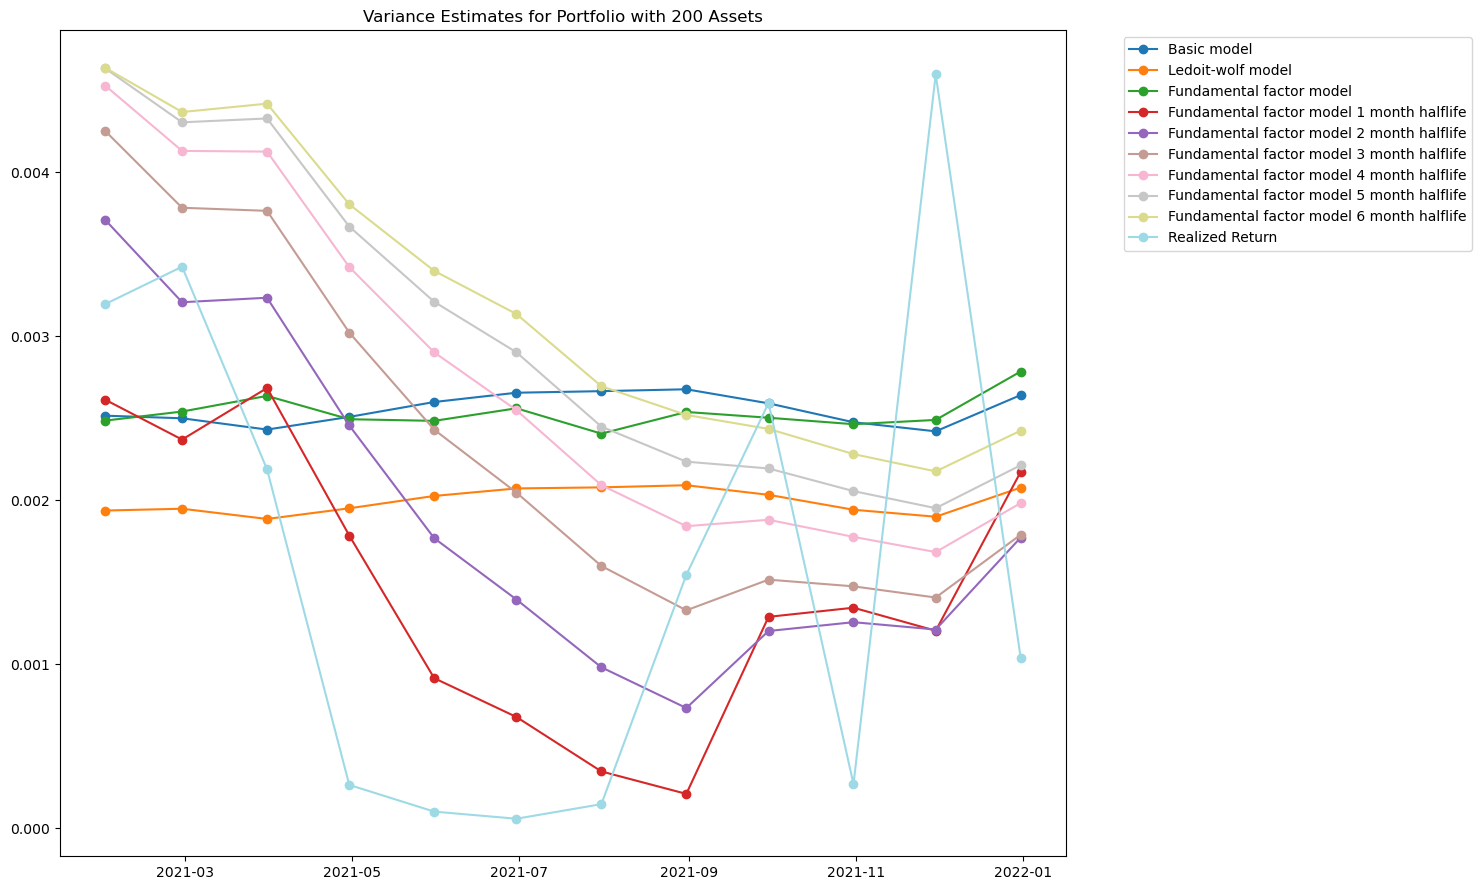

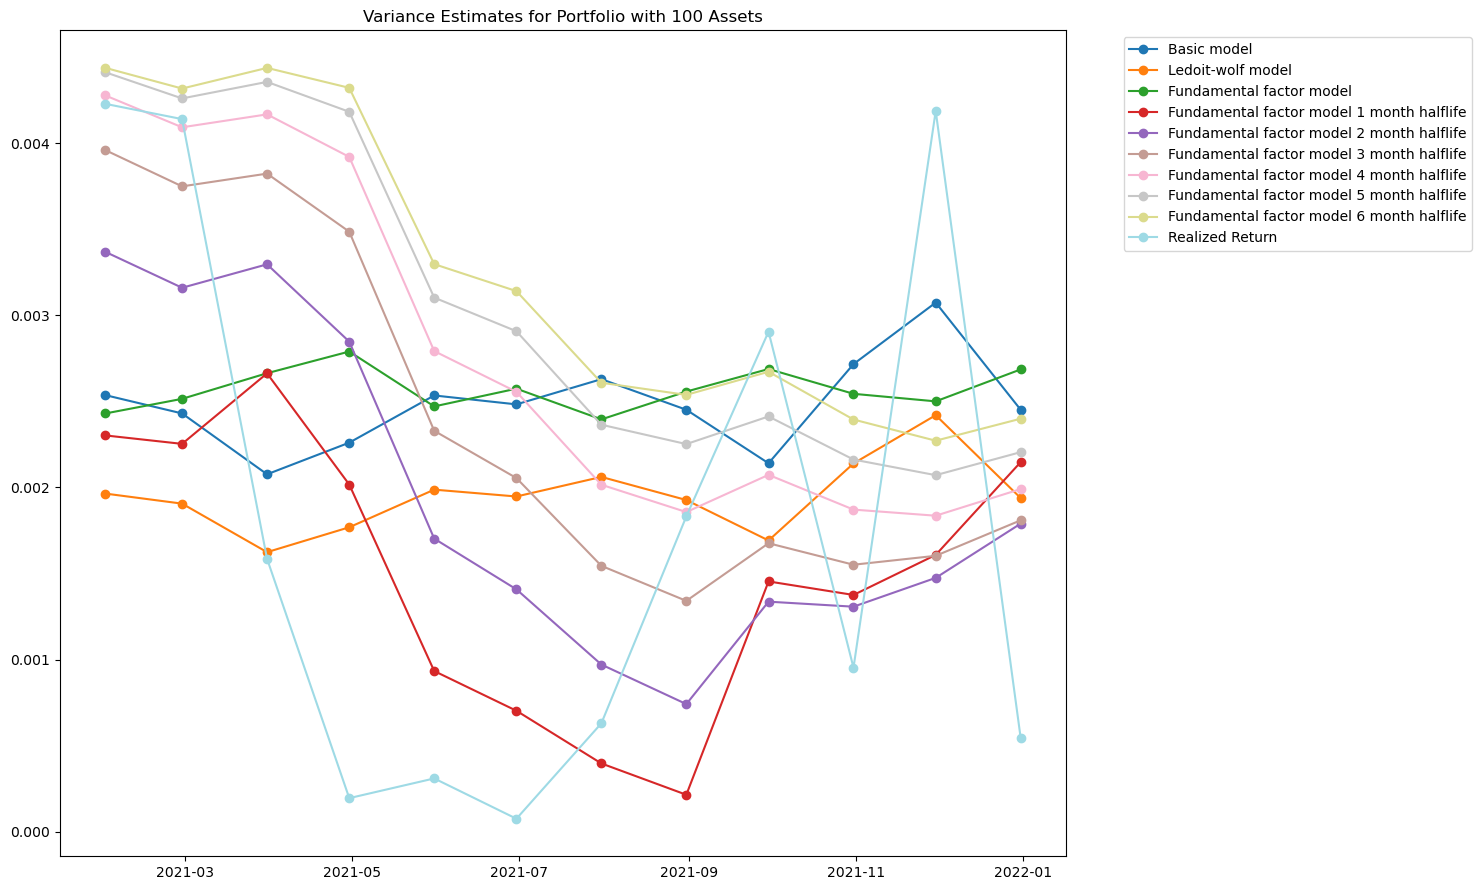

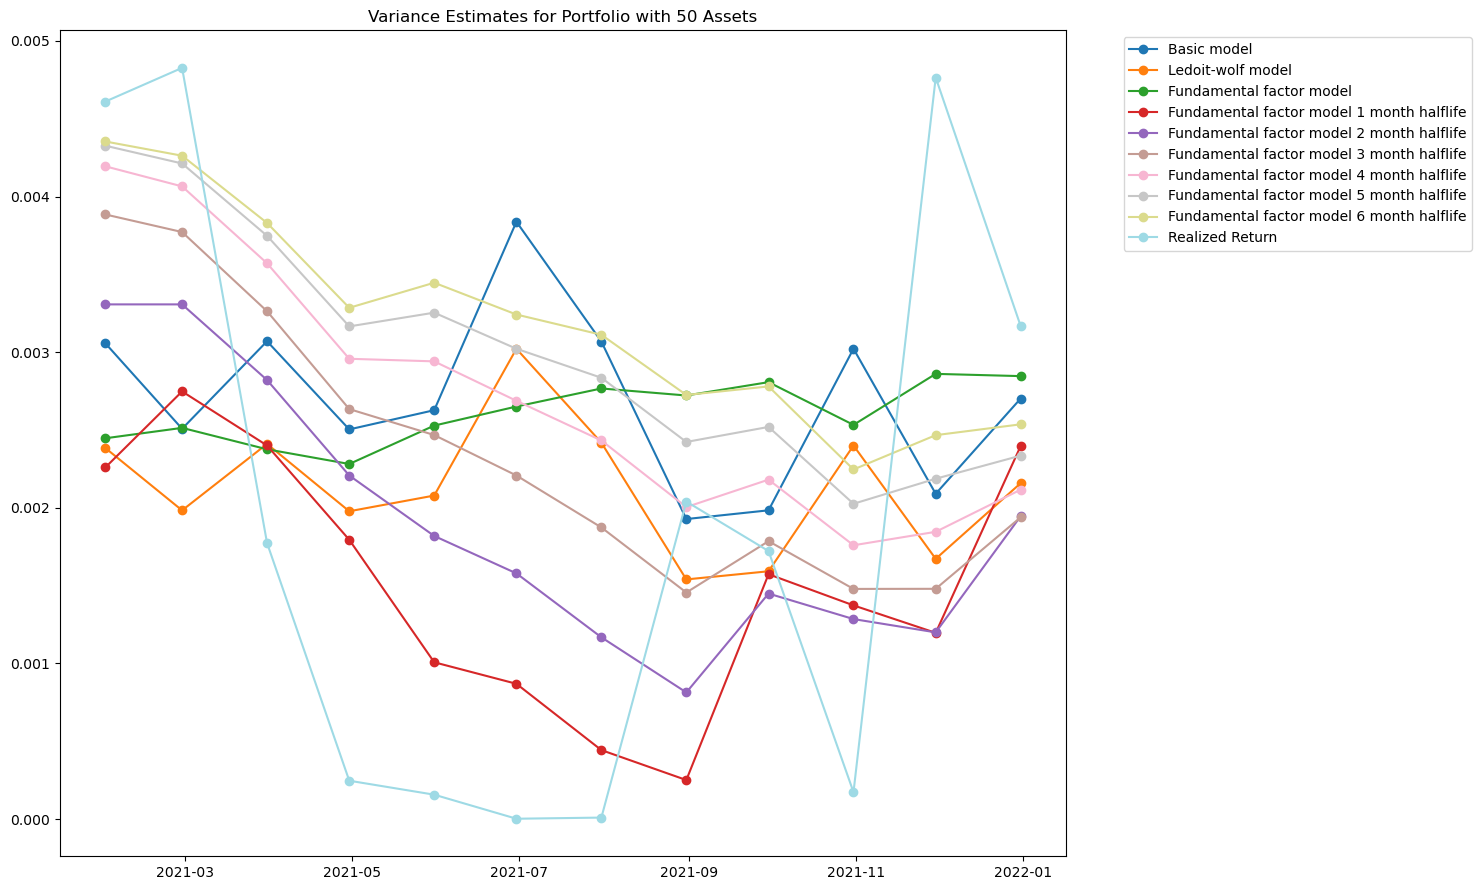

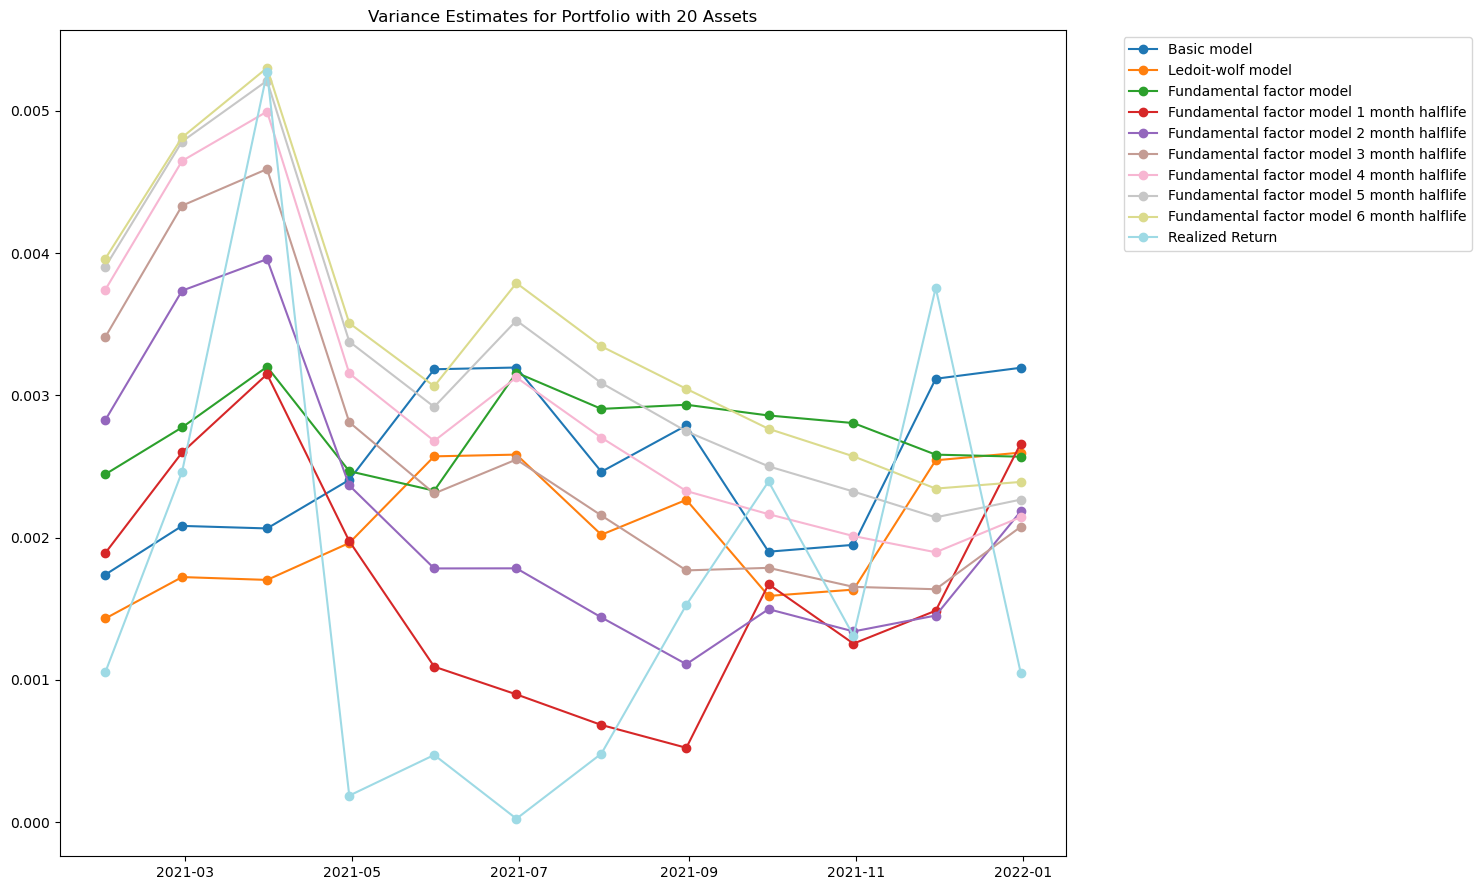

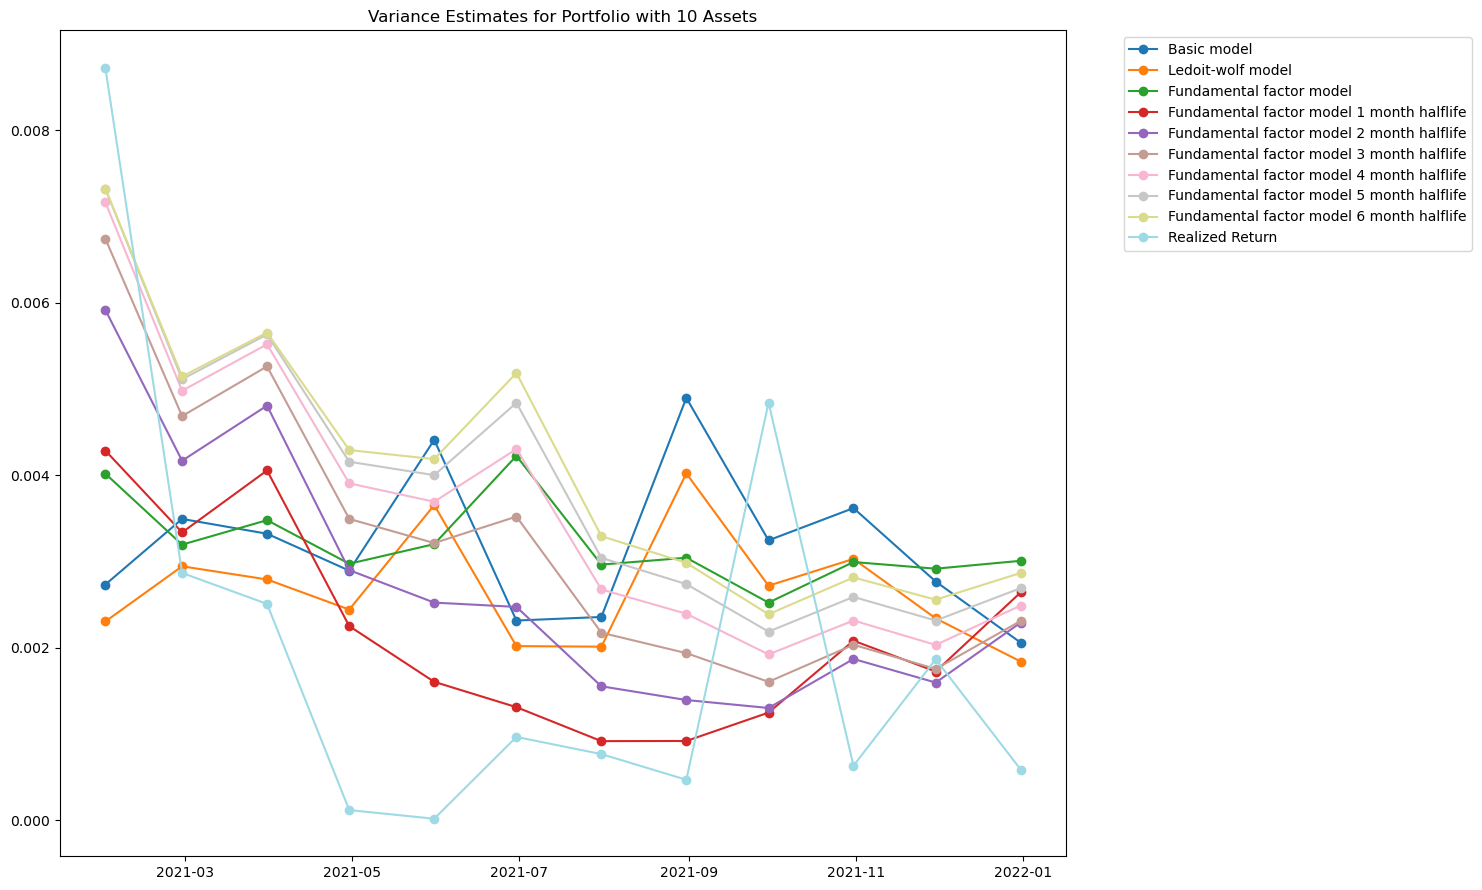

In [39]:
for n in n_assets:
    plot_volatility_estimates(trackers[n],models_dict,n)
    print("\n")